# 02 — Experiments at 64×64

**Goal:** establish the first full-dataset benchmarks at 64×64 and build the training pipeline that every later resolution (128x128, 224x224) reuses.

**Runs** (trained on the full 89,996-image training set; model selection on the 10,004-image validation set):

| Run | Model | Network input | Learning rate |
|---|---|---|---|
| 1 | Baseline CNN | 64×64 | 1e-3 |
| 2 | ResNet-18, from scratch | 64×64 | 1e-3 |
| 3 | ResNet-18, ImageNet-pretrained | 64×64 | 1e-4 |
| 4 | ResNet-18, ImageNet-pretrained | 64×64 upsampled to 224×224 | 1e-4 |

**Models**
- **Baseline CNN:** 4 blocks of 3×3 conv (padding 1) → BatchNorm → ReLU → 2×2 max-pool (32/64/128/256 channels), then global average pooling, dropout 0.3, and a linear layer to 9 classes (0.39M parameters). Global average pooling lets the same model run unchanged at 64, 128, and 224.
- **ResNet-18:** standard torchvision architecture, unmodified at every resolution, with the final layer replaced by a 9-class linear layer (11.2M parameters). At 64×64 its final feature map is 2×2, vs. 7×7 at 224×224.
- All models output logits; softmax is applied inside the cross-entropy loss.

**Upsampling experiment (run 4):** standard ResNet-18 shrinks its input 32×, so a 64×64 image ends as a 2×2 feature map, compared with 7×7 at 224. Upsampling adds no new detail, but it gives the network the input size it was designed for. Same data and model as run 3, but each batch is bilinearly resized to 224×224 before entering the network. This adds no new image detail, so comparing run 4 with run 3, and later with native 224×224, separates two effects: missing detail at low resolution vs. ResNet-18 shrinking small inputs too aggressively.

**Preprocessing** (per batch, on the GPU): uint8 → float in [0, 1]; random horizontal and vertical flips (training only); per-channel normalization with ImageNet mean/std for all models. Validation preprocessing is deterministic.

**Training:** Adam with L2 weight decay 1e-4, batch size 128, mixed precision, up to 30 epochs, seed 0. The learning rate is multiplied by 0.3 when validation macro-F1 has not improved for 2 epochs; training stops early after 6 epochs without improvement, keeping the best checkpoint by validation macro-F1. Train vs. validation learning curves (loss and macro-F1) guide bias-variance analysis.

**Evaluation:** validation macro-F1 (primary), accuracy, per-class precision/recall/F1, confusion matrix, training seconds per epoch, and inference throughput. The test set, which comes from a different clinical center, is locked in code until all experimental choices are final.

**Starting point:** the feasibility experiment (two-layer CNN, 3 epochs, 9,000-image balanced subset) reached 49.5% validation accuracy and 0.486 macro-F1. It establishes feasibility rather than serving as a matched benchmark.

**Next:** hyperparameters above are starting values to tune on validation; final comparisons will use three seeds per configuration.

In [1]:
%load_ext autoreload
%autoreload 2
# ^ picks up edits to src/*.py automatically, without restarting the kernel

import os
os.environ["TORCH_HOME"] = "/home/ec2-user/SageMaker/.cache/torch"  # keeps downloaded pretrained weights across restarts

import numpy as np
import torch
from src.data import load_split, CLASS_NAMES, DATA_ROOT
from src.engine import run_experiment
from src.report import load_results, results_table, plot_history, plot_confusion, per_class_table

print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PyTorch 2.10.0+cu128 | GPU: Tesla T4


## 1. Look at the training data
Class balance matters for interpreting accuracy vs. macro-F1: macro-F1 weights every class equally, accuracy weights every image equally.

In [2]:
x, y = load_split(DATA_ROOT, 64, "train")
print("train images:", x.shape, x.dtype)
counts = np.bincount(y, minlength=len(CLASS_NAMES))
for name, c in zip(CLASS_NAMES, counts):
    print(f"{name:40s} {c:6d}  ({c / len(y):.1%})")

train images: (89996, 64, 64, 3) uint8
adipose                                    9366  (10.4%)
background                                 9509  (10.6%)
debris                                    10360  (11.5%)
lymphocytes                               10401  (11.6%)
mucus                                      8006  (8.9%)
smooth muscle                             12182  (13.5%)
normal colon mucosa                        7886  (8.8%)
cancer-associated stroma                   9401  (10.4%)
colorectal adenocarcinoma epithelium      12885  (14.3%)


## 2. Smoke test
A few batches through each code path to confirm everything works before starting the long runs. Nothing is saved. The second line also downloads the ImageNet weights (~45 MB) and checks the 64→224 upsampling path.

In [3]:
_ = run_experiment("smoke_test", "baseline_cnn", epochs=2, limit_batches=20, save=False)
_ = run_experiment("smoke_test", "resnet18_pretrained", input_size=224, epochs=1, limit_batches=10, save=False)

=== smoke_test: baseline_cnn, data 64x64, network input 64x64, 0.39M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 1.192 acc 0.568 F1 0.547 | val loss 1.884 acc 0.259 F1 0.151 | 11s  *best
ep 02 | lr 1.0e-03 | train loss 0.830 acc 0.702 F1 0.691 | val loss 0.892 acc 0.653 F1 0.633 | 0s  *best
Best epoch 2: val acc 0.6531, val macro-F1 0.6335, 5s/epoch train, 28325 img/s inference. Saved: (not saved)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/ec2-user/SageMaker/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 207MB/s]


=== smoke_test: resnet18_pretrained, data 64x64, network input 224x224, 11.18M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.767 acc 0.743 F1 0.740 | val loss 4.423 acc 0.366 F1 0.311 | 3s  *best
Best epoch 1: val acc 0.3656, val macro-F1 0.3107, 2s/epoch train, 2566 img/s inference. Saved: (not saved)



## 3. The four runs

Shared settings: Adam with L2 weight decay 1e-4, batch size 128, up to 30 epochs. The learning rate is multiplied by 0.3 whenever validation macro-F1 stalls for 2 epochs, and training stops early after 6 epochs without improvement. The best checkpoint (by validation macro-F1) is saved to `~/SageMaker/checkpoints/`, and metrics go to `results/<run name>.json` every epoch.

**Learning rates:** 1e-3 for models trained from scratch and 1e-4 for the pretrained ResNet. A large learning rate on pretrained weights tends to wipe out what they learned on ImageNet. Both values are starting points to tune on validation later.

**Time:** runs 1–3 should take a few minutes each. Run 4 is the slow one, because the network processes 224×224 inputs. If the browser tab disconnects, training keeps going on the instance; check `results/` for progress.

In [4]:
COMMON = dict(data_size=64, epochs=30, batch_size=128, seed=0)

In [5]:
r1 = run_experiment("baseline_cnn_64", "baseline_cnn", lr=1e-3, **COMMON)

=== baseline_cnn_64: baseline_cnn, data 64x64, network input 64x64, 0.39M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.372 acc 0.873 F1 0.871 | val loss 0.334 acc 0.880 F1 0.885 | 10s  *best
ep 02 | lr 1.0e-03 | train loss 0.170 acc 0.943 F1 0.943 | val loss 0.138 acc 0.953 F1 0.953 | 10s  *best
ep 03 | lr 1.0e-03 | train loss 0.129 acc 0.957 F1 0.956 | val loss 0.151 acc 0.945 F1 0.945 | 10s
ep 04 | lr 1.0e-03 | train loss 0.110 acc 0.963 F1 0.963 | val loss 0.311 acc 0.901 F1 0.893 | 10s
ep 05 | lr 1.0e-03 | train loss 0.098 acc 0.967 F1 0.967 | val loss 0.125 acc 0.958 F1 0.956 | 10s  *best
ep 06 | lr 1.0e-03 | train loss 0.090 acc 0.970 F1 0.970 | val loss 0.224 acc 0.925 F1 0.919 | 10s
ep 07 | lr 1.0e-03 | train loss 0.081 acc 0.973 F1 0.973 | val loss 0.403 acc 0.873 F1 0.861 | 10s
ep 08 | lr 1.0e-03 | train loss 0.075 acc 0.975 F1 0.975 | val loss 0.117 acc 0.959 F1 0.958 | 10s  *best
ep 09 | lr 1.0e-03 | train loss 0.071 acc 0.977 F1 0.976 | val loss 0.102 acc 0.96

In [6]:
r2 = run_experiment("resnet18_scratch_64", "resnet18_scratch", lr=1e-3, **COMMON)

=== resnet18_scratch_64: resnet18_scratch, data 64x64, network input 64x64, 11.18M params, device cuda ===
ep 01 | lr 1.0e-03 | train loss 0.480 acc 0.829 F1 0.828 | val loss 2.498 acc 0.449 F1 0.389 | 17s  *best
ep 02 | lr 1.0e-03 | train loss 0.237 acc 0.919 F1 0.919 | val loss 0.646 acc 0.824 F1 0.823 | 16s  *best
ep 03 | lr 1.0e-03 | train loss 0.179 acc 0.940 F1 0.940 | val loss 0.598 acc 0.817 F1 0.805 | 16s
ep 04 | lr 1.0e-03 | train loss 0.146 acc 0.951 F1 0.951 | val loss 0.277 acc 0.909 F1 0.906 | 17s  *best
ep 05 | lr 1.0e-03 | train loss 0.130 acc 0.956 F1 0.956 | val loss 1.019 acc 0.766 F1 0.727 | 17s
ep 06 | lr 1.0e-03 | train loss 0.131 acc 0.957 F1 0.956 | val loss 2.897 acc 0.534 F1 0.489 | 16s
ep 07 | lr 1.0e-03 | train loss 0.111 acc 0.962 F1 0.962 | val loss 0.354 acc 0.895 F1 0.882 | 16s
ep 08 | lr 3.0e-04 | train loss 0.061 acc 0.980 F1 0.980 | val loss 0.088 acc 0.970 F1 0.970 | 16s  *best
ep 09 | lr 3.0e-04 | train loss 0.055 acc 0.981 F1 0.981 | val loss 0.123

In [7]:
r3 = run_experiment("resnet18_pretrained_64", "resnet18_pretrained", lr=1e-4, **COMMON)

=== resnet18_pretrained_64: resnet18_pretrained, data 64x64, network input 64x64, 11.18M params, device cuda ===
ep 01 | lr 1.0e-04 | train loss 0.195 acc 0.936 F1 0.936 | val loss 0.082 acc 0.975 F1 0.975 | 17s  *best
ep 02 | lr 1.0e-04 | train loss 0.081 acc 0.973 F1 0.973 | val loss 0.063 acc 0.981 F1 0.981 | 16s  *best
ep 03 | lr 1.0e-04 | train loss 0.055 acc 0.982 F1 0.982 | val loss 0.046 acc 0.985 F1 0.985 | 17s  *best
ep 04 | lr 1.0e-04 | train loss 0.045 acc 0.985 F1 0.985 | val loss 0.042 acc 0.987 F1 0.987 | 17s  *best
ep 05 | lr 1.0e-04 | train loss 0.036 acc 0.988 F1 0.988 | val loss 0.043 acc 0.985 F1 0.985 | 16s
ep 06 | lr 1.0e-04 | train loss 0.031 acc 0.990 F1 0.990 | val loss 0.052 acc 0.982 F1 0.982 | 17s
ep 07 | lr 1.0e-04 | train loss 0.028 acc 0.991 F1 0.991 | val loss 0.039 acc 0.988 F1 0.988 | 16s  *best
ep 08 | lr 1.0e-04 | train loss 0.027 acc 0.991 F1 0.991 | val loss 0.039 acc 0.987 F1 0.987 | 16s
ep 09 | lr 1.0e-04 | train loss 0.023 acc 0.992 F1 0.992 | v

### Run 4: upsampling experiment
Same data and model as run 3. The only change is `input_size=224`: each 64×64 batch is resized to 224×224 on the GPU (bilinear interpolation) right before it enters the network.

In [8]:
r4 = run_experiment("resnet18_pretrained_64up224", "resnet18_pretrained", lr=1e-4, input_size=224, **COMMON)

=== resnet18_pretrained_64up224: resnet18_pretrained, data 64x64, network input 224x224, 11.18M params, device cuda ===
ep 01 | lr 1.0e-04 | train loss 0.102 acc 0.968 F1 0.968 | val loss 0.027 acc 0.993 F1 0.993 | 112s  *best
ep 02 | lr 1.0e-04 | train loss 0.033 acc 0.989 F1 0.989 | val loss 0.069 acc 0.977 F1 0.977 | 112s
ep 03 | lr 1.0e-04 | train loss 0.023 acc 0.992 F1 0.992 | val loss 0.022 acc 0.993 F1 0.993 | 112s  *best
ep 04 | lr 1.0e-04 | train loss 0.018 acc 0.994 F1 0.994 | val loss 0.023 acc 0.994 F1 0.994 | 112s  *best
ep 05 | lr 1.0e-04 | train loss 0.017 acc 0.995 F1 0.995 | val loss 0.019 acc 0.994 F1 0.994 | 112s  *best
ep 06 | lr 1.0e-04 | train loss 0.016 acc 0.995 F1 0.995 | val loss 0.025 acc 0.993 F1 0.993 | 112s
ep 07 | lr 1.0e-04 | train loss 0.013 acc 0.996 F1 0.996 | val loss 0.020 acc 0.993 F1 0.993 | 112s
ep 08 | lr 1.0e-04 | train loss 0.014 acc 0.996 F1 0.996 | val loss 0.026 acc 0.993 F1 0.993 | 112s
ep 09 | lr 3.0e-05 | train loss 0.004 acc 0.999 F1 0

## 4. Compare
These cells read the saved `results/*.json` files, so they work after a kernel restart without retraining.

In [9]:
RUNS = ["baseline_cnn_64", "resnet18_scratch_64", "resnet18_pretrained_64", "resnet18_pretrained_64up224"]
results = load_results(RUNS)
results_table(results)

,model,data,net input,params (M),best epoch,epochs run,val acc,val macro-F1,train s/epoch,inference img/s,status
run,,,,,,,,,,,
baseline_cnn_64,baseline_cnn,64,64,0.39,28,30,0.9952,0.9953,9.5,31652,done
resnet18_scratch_64,resnet18_scratch,64,64,11.18,27,30,0.9945,0.9945,15.9,20654,done
resnet18_pretrained_64,resnet18_pretrained,64,64,11.18,28,30,0.9954,0.9953,16.0,20653,done
resnet18_pretrained_64up224,resnet18_pretrained,64,224,11.18,20,26,0.9993,0.9993,107.9,2599,done


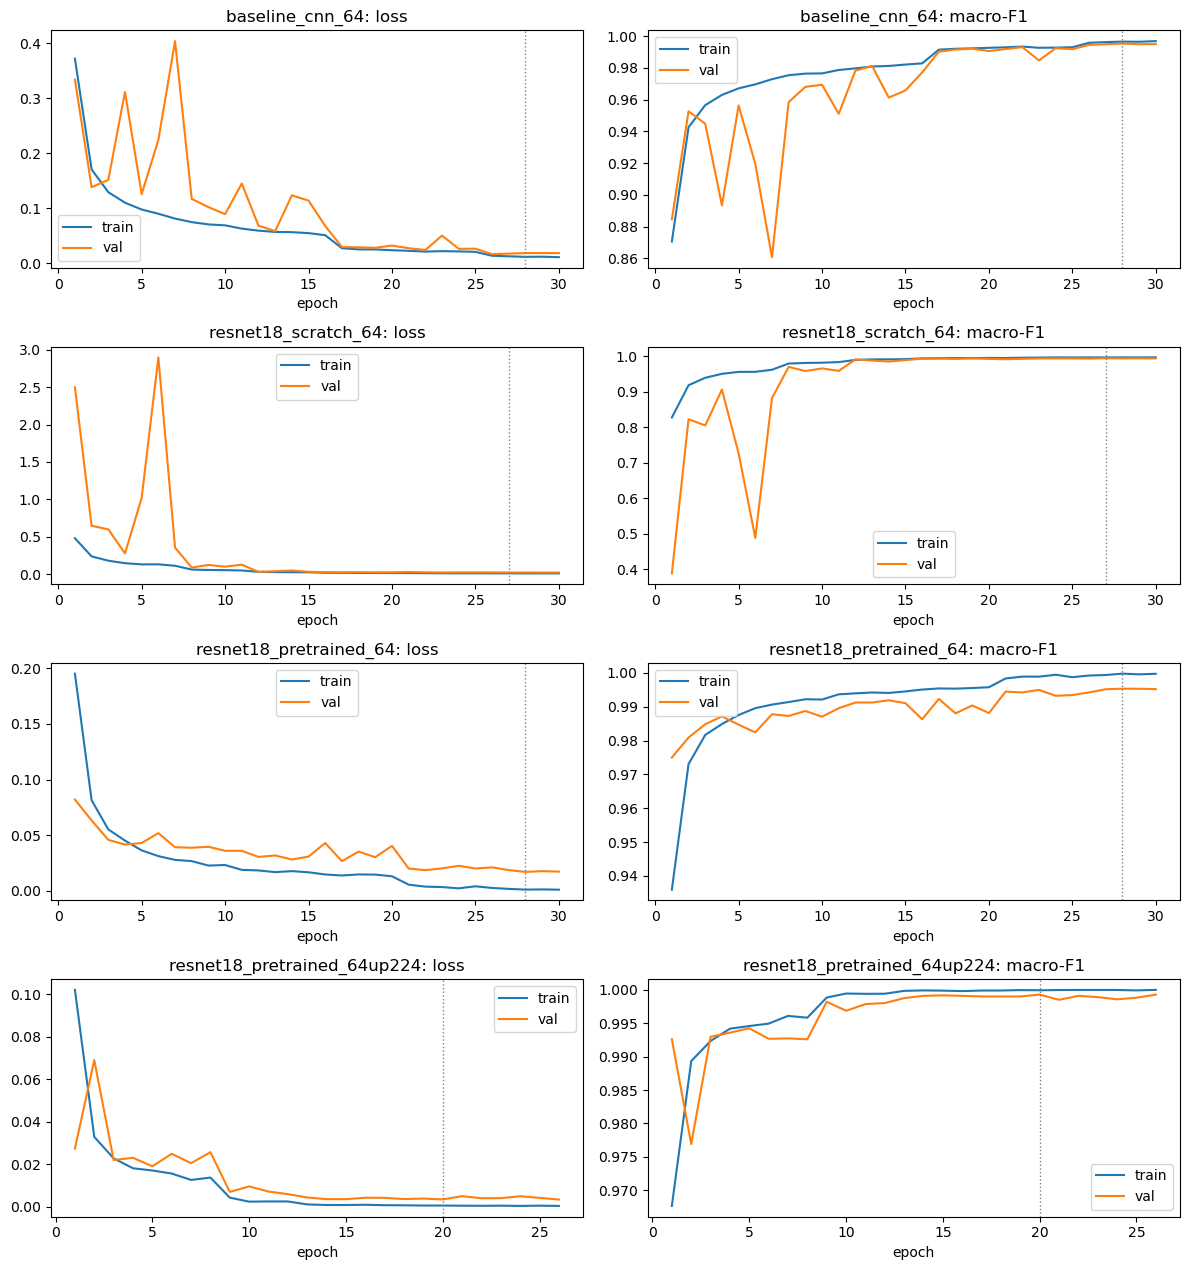

In [10]:
plot_history(results);

,precision,recall,F1
adipose,1.000,1.000,1.000
background,1.000,1.000,1.000
debris,1.000,0.999,1.000
lymphocytes,1.000,1.000,1.000
mucus,0.996,0.998,0.997
smooth muscle,1.000,1.000,1.000
normal colon mucosa,1.000,1.000,1.000
cancer-associated stroma,1.000,0.998,0.999
colorectal adenocarcinoma epithelium,0.998,0.999,0.998


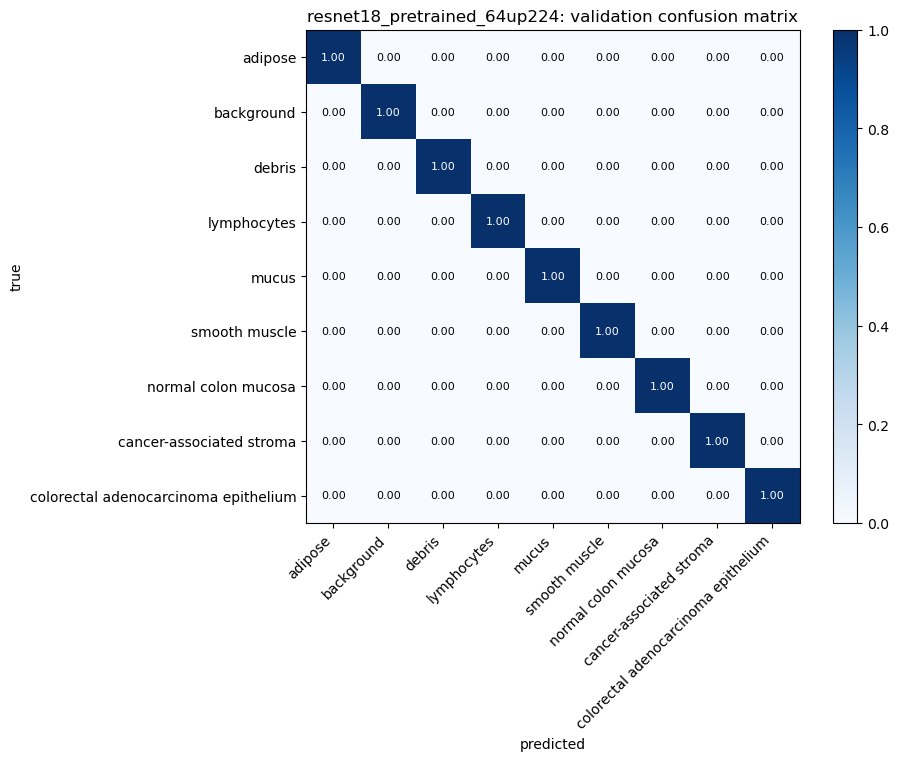

In [11]:
best = max(results, key=lambda r: r["best_val"]["macro_f1"])
plot_confusion(best);
per_class_table(best)

### What to look for
- **Bias vs. variance:** in the learning curves, a widening gap between train and val means overfitting (more regularization or augmentation may help). Both curves flattening at a low level means underfitting (a bigger model or longer training may help).
- **Run 3 vs. run 2:** how much ImageNet pretraining helps on histology images.
- **Run 4 vs. run 3:** whether giving ResNet-18 its intended input size helps at the same 64×64 information level. Revisit this once native 224×224 results exist.
- **Baseline vs. ResNets:** whether a small purpose-built CNN is competitive, and at what cost (the table shows parameters, seconds per epoch, and inference speed).
- **Confusion matrix:** which tissue types get mixed up. These pairs are the place to look at misclassified examples later.

## 5. Save to GitHub
In a terminal (run one line at a time):
```
cd ~/SageMaker/cs230-pathmnist
git add src 02_experiments_64.ipynb results
git commit -m "64x64 experiments: baseline CNN, ResNet-18 scratch/pretrained, upsampling"
git push
```